In [ ]:
!pip install -q opencv-python-headless numpy matplotlib scikit-learn joblib

In [ ]:
import os, shutil, zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt
import joblib
from google.colab import files

IMG_SIZE = 64
CLASSES = ["Paper", "Rock", "Scissors"]    # label 0, 1, 2
VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp")

In [ ]:
uploaded = files.upload()
zip_name = list(uploaded.keys())[0]

# Check if the uploaded file is a valid zip archive
if not zipfile.is_zipfile(zip_name):
    raise ValueError(f"Error: '{zip_name}' is not a valid ZIP file. Please compress your Paper, Rock, and Scissors dataset folders into a single .zip file and upload that archive.")

if os.path.exists("dataset"): shutil.rmtree("dataset")
with zipfile.ZipFile(zip_name) as z:
    z.extractall("dataset")

# find the folder that directly contains Paper / Rock / Scissors
DATASET_DIR = None
for r, dirs, _ in os.walk("dataset"):
    if all(c in dirs for c in CLASSES):
        DATASET_DIR = r
        break

assert DATASET_DIR, "Paper/Rock/Scissors folders not found. Check the zip structure."
print("Using folder:", DATASET_DIR)
for c in CLASSES:
    n = len([f for f in os.listdir(f"{DATASET_DIR}/{c}") if f.lower().endswith(VALID_EXT)])
    print(f"{c}: {n} images")

Saving dataset (2).zip to dataset (2).zip
Using folder: dataset
Paper: 150 images
Rock: 150 images
Scissors: 150 images


In [ ]:
def preprocess(img_bgr):
    img = cv2.resize(img_bgr, (IMG_SIZE, IMG_SIZE))
    return img.astype(np.float32).flatten() / 255.0

X, y = [], []
for label, c in enumerate(CLASSES):
    folder = f"{DATASET_DIR}/{c}"
    for f in os.listdir(folder):
        if not f.lower().endswith(VALID_EXT):
            continue
        img = cv2.imread(os.path.join(folder, f))
        if img is None:
            print("Skipping unreadable image:", f)
            continue
        X.append(preprocess(img))
        y.append(label)

X = np.array(X, dtype=np.float32)
y = np.array(y)
print("Feature matrix:", X.shape)
print("Label array:", y.shape)

Feature matrix: (450, 12288)
Label array: (450,)


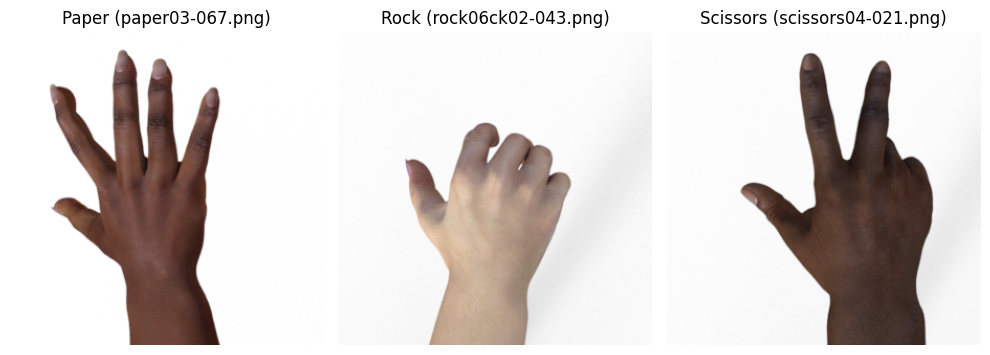

In [ ]:
import matplotlib.pyplot as plt
import random

plt.figure(figsize=(10, 4))
for i, c in enumerate(CLASSES):
    folder = f"{DATASET_DIR}/{c}"
    images = [f for f in os.listdir(folder) if f.lower().endswith(VALID_EXT)]

    if images:
        # Choose a random image from the category
        random_img_name = random.choice(images)
        img_path = os.path.join(folder, random_img_name)
        img_bgr = cv2.imread(img_path)

        if img_bgr is not None:
            # Convert BGR (OpenCV format) to RGB (Matplotlib format)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

            plt.subplot(1, 3, i + 1)
            plt.imshow(img_rgb)
            plt.title(f"{c} ({random_img_name})")
            plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 360
Testing samples : 90


In [ ]:
from sklearn.svm import SVC

model = SVC(kernel="linear", probability=True, random_state=42)
model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)
for a, p in zip(y_test[:10], y_pred[:10]):
    print(f"Actual: {CLASSES[a]}, Predicted: {CLASSES[p]}")

accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy: {accuracy:.2%}\n")
print(classification_report(y_test, y_pred, target_names=CLASSES, zero_division=0))

Actual: Scissors, Predicted: Scissors
Actual: Paper, Predicted: Paper
Actual: Rock, Predicted: Rock
Actual: Scissors, Predicted: Scissors
Actual: Rock, Predicted: Rock
Actual: Scissors, Predicted: Scissors
Actual: Scissors, Predicted: Scissors
Actual: Rock, Predicted: Rock
Actual: Rock, Predicted: Rock
Actual: Paper, Predicted: Paper

Model Accuracy: 98.89%

              precision    recall  f1-score   support

       Paper       1.00      0.97      0.98        30
        Rock       0.97      1.00      0.98        30
    Scissors       1.00      1.00      1.00        30

    accuracy                           0.99        90
   macro avg       0.99      0.99      0.99        90
weighted avg       0.99      0.99      0.99        90



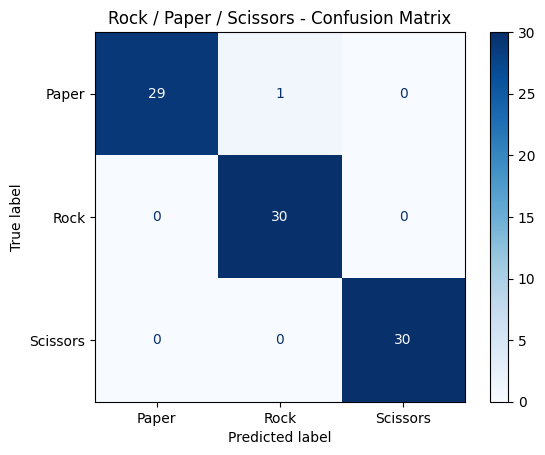

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", values_format="d")
plt.title("Rock / Paper / Scissors - Confusion Matrix")
plt.show()

Saving Screenshot 2026-11-10 221414.png to Screenshot 2026-11-10 221414.png


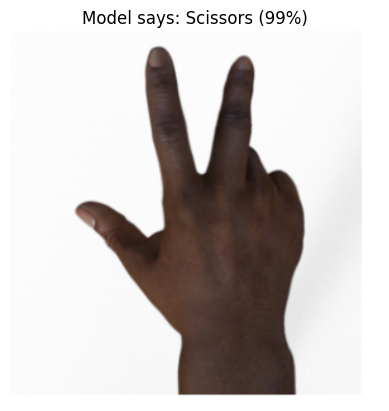

In [ ]:
up = files.upload()
fname = list(up.keys())[0]
test_img = cv2.imread(fname)

proba = model.predict_proba([preprocess(test_img)])[0]
pred = int(np.argmax(proba))
plt.imshow(cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB))
plt.title(f"Model says: {CLASSES[pred]} ({proba[pred]:.0%})")
plt.axis("off"); plt.show()

In [ ]:
joblib.dump({"model": model, "classes": CLASSES, "img_size": IMG_SIZE,
             "accuracy": float(accuracy)}, "rps_model.joblib")
files.download("rps_model.joblib")
print("Model saved successfully.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved successfully.


In [ ]:
print("Project        : Rock / Paper / Scissors classifier")
print("Model          : Linear SVM, 64 x 64 pixels")
print("Total images   :", len(y))
print("Train / Test   :", len(X_train), "/", len(X_test))
print(f"Model Accuracy : {accuracy:.2%}")

Project        : Rock / Paper / Scissors classifier
Model          : Linear SVM, 64 x 64 pixels
Total images   : 450
Train / Test   : 360 / 90
Model Accuracy : 98.89%
